# Task 4 - Fine-tuning Xception and ResNet-50 (motif of `transfer_learning_all.py`)

## Plan

The motif script is the classic two-step Keras recipe: load an ImageNet backbone without its top, freeze it,
put `GlobalAveragePooling2D -> Dense(256, ReLU) -> Dropout(0.5) -> Dense(classes, softmax)` on top, train with
Adam and categorical cross-entropy. This notebook keeps that head and that first step, then adds the
fine-tuning step the motif stops short of.

| Step | Backbone layers trained | Optimizer | Epochs | Selection |
|---|---|---|---|---|
| Stage 1 (the motif as is) | none | Adam 1e-3 | 10 | best val macro F1 |
| Stage 2a `top` | last stage: Xception exit flow (block13-14), ResNet-50 conv5 | Adam 1e-5 | up to 20, stop after 5 without a better val macro F1 | best val macro F1 |
| Stage 2b `all` | every layer | Adam 1e-5 | up to 20, same stopping | best val macro F1 |

Both stage-2 variants start from the same stage-1 weights, so `top` vs `all` isolates how much of the
backbone to adapt. Choices behind the plan:

- **Head first, then a low learning rate.** A random head sends large gradients into the backbone and
  wrecks the pretrained features; training the head first (stage 1) and then fine-tuning at 1e-5 avoids it.
- **BatchNorm stays frozen.** The backbone is always called with `training=False` and its BatchNorm layers
  are not trainable, so batch statistics from 32 images never overwrite the ImageNet ones.
- **Mixed precision (float16)** so the full backbone fits in the 6 GB GPU at batch 32; the output layer
  stays float32.
- **Selection on validation only**; the test split is predicted once per run, after training.

Changes from the motif, all forced by the data: CIFAR-10 -> this dataset through the shared pipeline (so no
`Resizing` and no `ImageDataGenerator`; rescaling follows each backbone), VGG16 -> Xception and ResNet-50,
10 -> 4 classes, and the test set used as `validation_data` -> the real validation split.

**Data.** Same pipeline as every other task (`src/data.py`, the transfer-learning branch protocol): `data/split_aspect.csv` (Kaggle test kept; Kaggle train+val re-split 800/200 per class, stratified by aspect group), square crop from the raw image (random on train, center on val/test) resized to 224x224, train-only affine/flip/brightness/contrast augmentation, and aspect-balanced sampling. Batches arrive as [0, 255] pixels; the model rescales them itself. The best epoch is picked on validation; test is predicted once at the end.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import keras
import pandas as pd
from keras import layers

import config
from src import data, experiment

experiment.setup(mixed_precision=True)
frames, datasets = data.load_datasets()
{split: len(frame) for split, frame in frames.items()}

I0000 00:00:1791569631.934577   46818 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791569631.976535   46818 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791569633.013608   46818 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | policy: mixed_float16


I0000 00:00:1791569634.452444   46818 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


{'train': 3200, 'val': 800, 'test': 800}

In [2]:
def build_motif(name):
    base, preprocess = experiment.backbone(name)
    inputs = keras.Input((config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
    x = base(preprocess(inputs), training=False)   # the backbone ends with GlobalAveragePooling2D
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(config.CLASS_NAMES), activation="softmax", dtype="float32")(x)
    return keras.Model(inputs, outputs, name=f"motif_{name}"), base


STAGE1 = {"optimizer": "Adam 1e-3", "epochs": 10, "selection": "val macro F1"}
STAGE2 = {"optimizer": "Adam 1e-5", "epochs": 20, "early_stopping": "val macro F1, patience 5",
          "selection": "val macro F1", "batchnorm": "frozen (inference mode)", "precision": "mixed_float16"}

## Run the plan for both backbones

=== ft_stage1_xception: 525,572 trainable parameters
Epoch 1/10


I0000 00:00:1791569636.531304   46818 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


I0000 00:00:1791569638.861885   46874 cuda_dnn.cc:461] Loaded cuDNN version 92000


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 22s - 215ms/step - accuracy: 0.7356 - f1: 0.7295 - loss: 0.6456 - val_accuracy: 0.8200 - val_f1: 0.8203 - val_loss: 0.4208


...

Epoch 9/10


I0000 00:00:1791569808.115078   46938 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5331905743700333275
I0000 00:00:1791569808.115141   46938 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 8079042129986120851
I0000 00:00:1791569808.115154   46938 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 4607357747485596390


100/100 - 19s - 187ms/step - accuracy: 0.8797 - f1: 0.8747 - loss: 0.3063 - val_accuracy: 0.8800 - val_f1: 0.8786 - val_loss: 0.3267


Epoch 10/10


100/100 - 17s - 168ms/step - accuracy: 0.8725 - f1: 0.8699 - loss: 0.3149 - val_accuracy: 0.8737 - val_f1: 0.8737 - val_loss: 0.2891


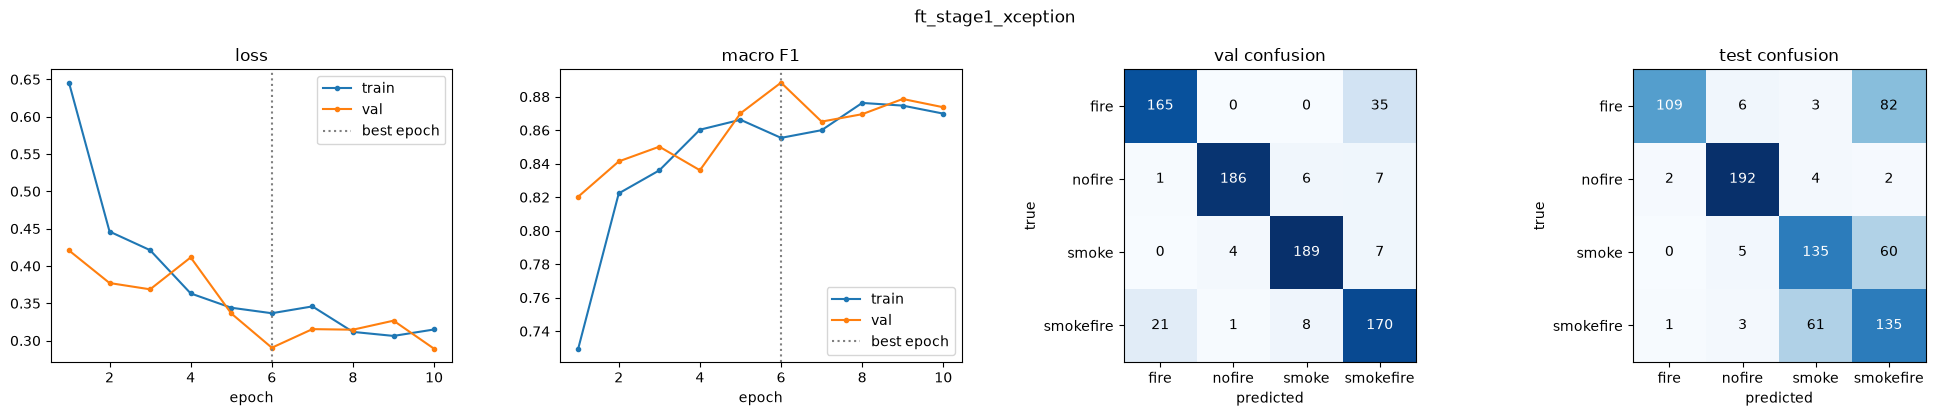

=== ft_top_xception: 7,301,236 trainable parameters
Epoch 1/20


W0000 00:00:1791569844.167909   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 6.78GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


W0000 00:00:1791569844.386971   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 3.40GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


W0000 00:00:1791569844.732410   46872 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


...

100/100 - 20s - 200ms/step - accuracy: 0.9434 - f1: 0.9406 - loss: 0.1462 - val_accuracy: 0.9312 - val_f1: 0.9314 - val_loss: 0.1700


Epoch 19/20


100/100 - 23s - 229ms/step - accuracy: 0.9500 - f1: 0.9462 - loss: 0.1276 - val_accuracy: 0.9375 - val_f1: 0.9375 - val_loss: 0.1711


Epoch 20/20


100/100 - 22s - 220ms/step - accuracy: 0.9475 - f1: 0.9448 - loss: 0.1346 - val_accuracy: 0.9337 - val_f1: 0.9340 - val_loss: 0.1658


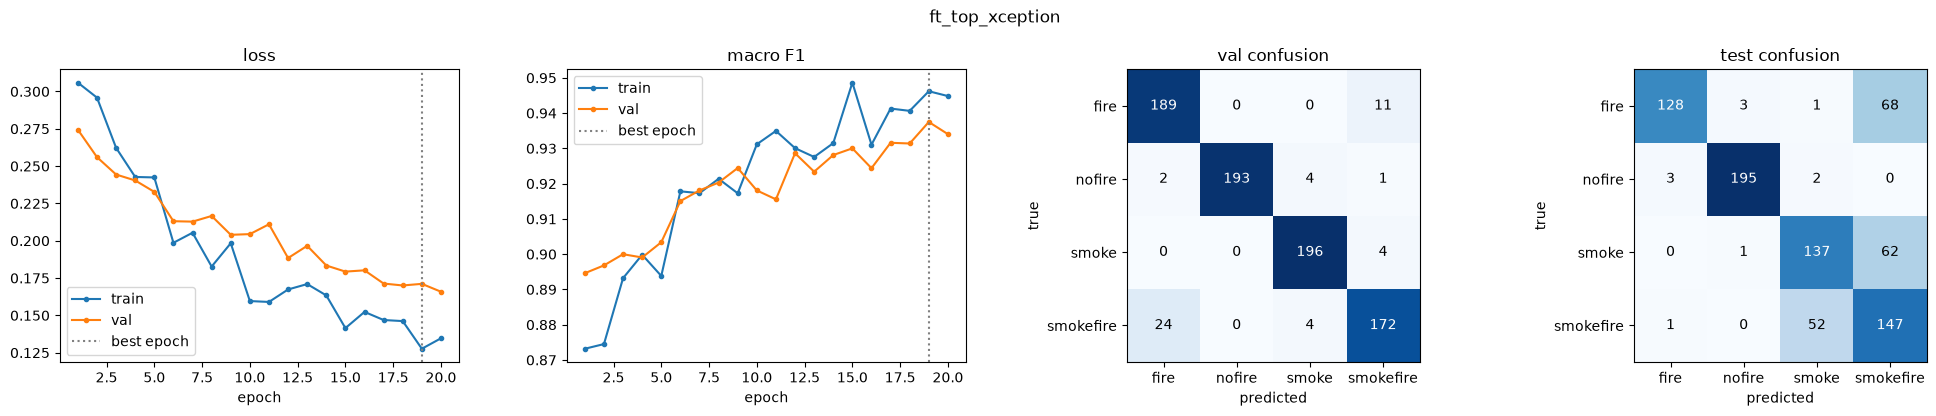

=== ft_all_xception: 21,277,996 trainable parameters
Epoch 1/20


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 28 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


W0000 00:00:1791570366.600432   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.38GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


W0000 00:00:1791570366.920034   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.59GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


W0000 00:00:1791570367.330709   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.17GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


...

I0000 00:00:1791571236.809773   50736 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 15439736617729860644


100/100 - 47s - 470ms/step - accuracy: 0.9931 - f1: 0.9923 - loss: 0.0228 - val_accuracy: 0.9688 - val_f1: 0.9688 - val_loss: 0.1039


Epoch 20/20


I0000 00:00:1791571283.844365   50736 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 15439736617729860644


100/100 - 45s - 446ms/step - accuracy: 0.9919 - f1: 0.9915 - loss: 0.0234 - val_accuracy: 0.9650 - val_f1: 0.9652 - val_loss: 0.1218


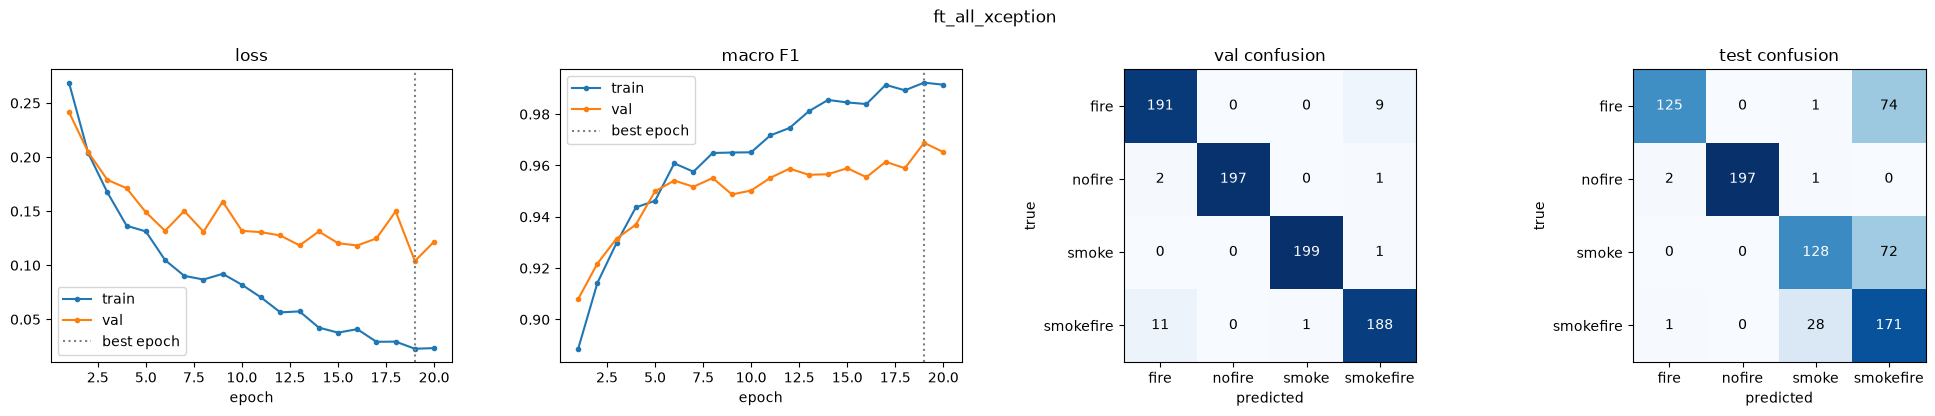

=== ft_stage1_resnet50: 525,572 trainable parameters
Epoch 1/10


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 27s - 268ms/step - accuracy: 0.7875 - f1: 0.7822 - loss: 0.5488 - val_accuracy: 0.9100 - val_f1: 0.9098 - val_loss: 0.2435


Epoch 2/10


100/100 - 39s - 394ms/step - accuracy: 0.8928 - f1: 0.8884 - loss: 0.2912 - val_accuracy: 0.9100 - val_f1: 0.9096 - val_loss: 0.2357


...

100/100 - 20s - 203ms/step - accuracy: 0.9219 - f1: 0.9197 - loss: 0.2068 - val_accuracy: 0.9463 - val_f1: 0.9460 - val_loss: 0.1591


Epoch 9/10


100/100 - 18s - 180ms/step - accuracy: 0.9375 - f1: 0.9339 - loss: 0.1672 - val_accuracy: 0.9287 - val_f1: 0.9289 - val_loss: 0.1843


Epoch 10/10


100/100 - 20s - 197ms/step - accuracy: 0.9366 - f1: 0.9326 - loss: 0.1707 - val_accuracy: 0.9388 - val_f1: 0.9381 - val_loss: 0.1540


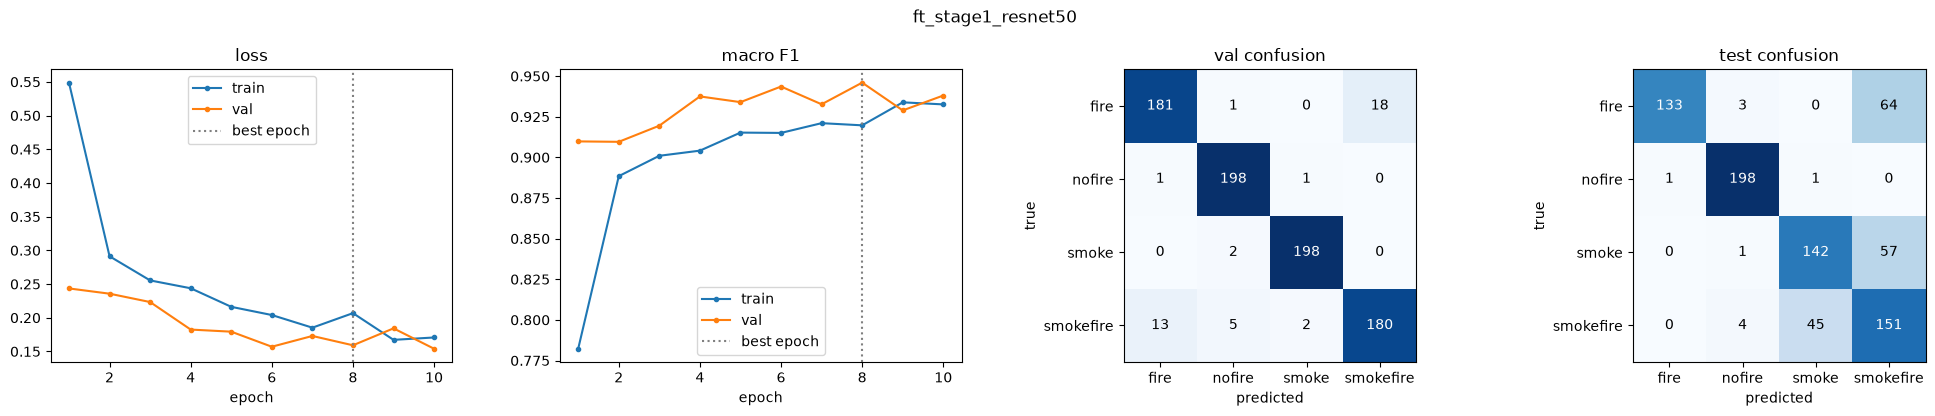

=== ft_top_resnet50: 15,479,044 trainable parameters
Epoch 1/20


W0000 00:00:1791571537.062520   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.28GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


W0000 00:00:1791571537.431142   46872 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.27GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 33s - 334ms/step - accuracy: 0.9453 - f1: 0.9423 - loss: 0.1430 - val_accuracy: 0.9525 - val_f1: 0.9526 - val_loss: 0.1260


...

100/100 - 23s - 228ms/step - accuracy: 0.9841 - f1: 0.9830 - loss: 0.0503 - val_accuracy: 0.9613 - val_f1: 0.9613 - val_loss: 0.1016


Epoch 11/20


100/100 - 23s - 235ms/step - accuracy: 0.9859 - f1: 0.9848 - loss: 0.0397 - val_accuracy: 0.9625 - val_f1: 0.9625 - val_loss: 0.1059


Epoch 12/20


100/100 - 24s - 237ms/step - accuracy: 0.9878 - f1: 0.9868 - loss: 0.0337 - val_accuracy: 0.9700 - val_f1: 0.9700 - val_loss: 0.1022


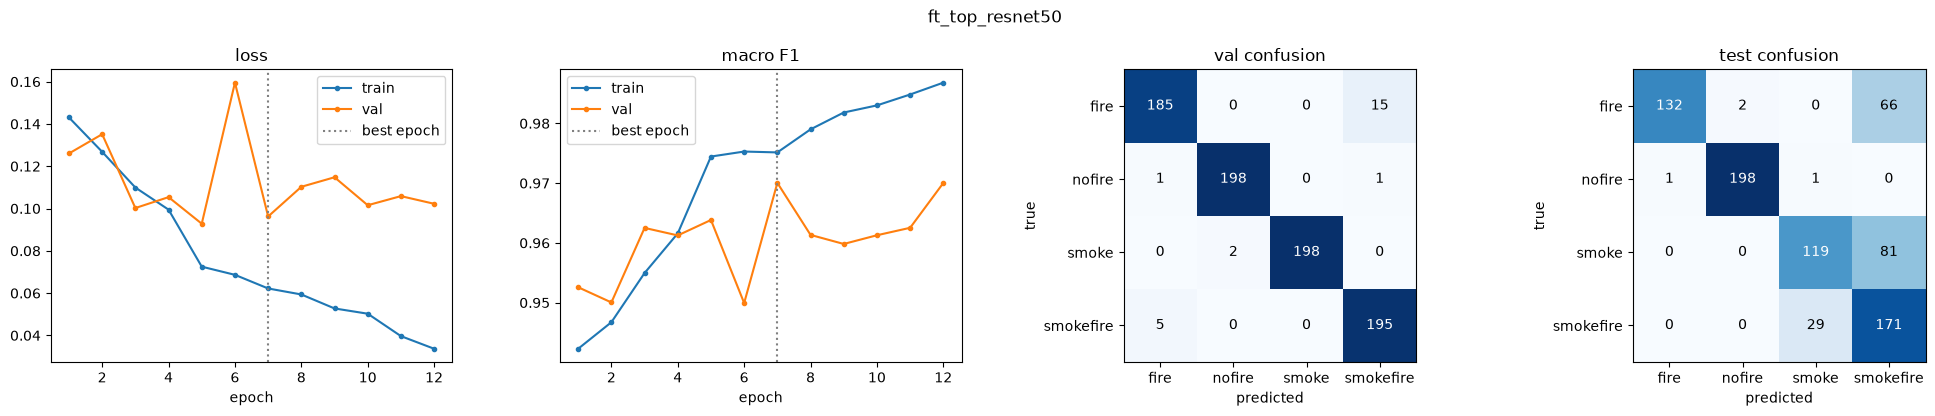

=== ft_all_resnet50: 24,007,044 trainable parameters
Epoch 1/20


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 50 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 59s - 587ms/step - accuracy: 0.9413 - f1: 0.9383 - loss: 0.1521 - val_accuracy: 0.9388 - val_f1: 0.9384 - val_loss: 0.1428


Epoch 2/20


...

100/100 - 42s - 421ms/step - accuracy: 0.9866 - f1: 0.9854 - loss: 0.0391 - val_accuracy: 0.9650 - val_f1: 0.9651 - val_loss: 0.0960


Epoch 9/20


100/100 - 40s - 397ms/step - accuracy: 0.9878 - f1: 0.9869 - loss: 0.0333 - val_accuracy: 0.9675 - val_f1: 0.9675 - val_loss: 0.1005


Epoch 10/20


100/100 - 41s - 412ms/step - accuracy: 0.9859 - f1: 0.9850 - loss: 0.0429 - val_accuracy: 0.9650 - val_f1: 0.9649 - val_loss: 0.0988


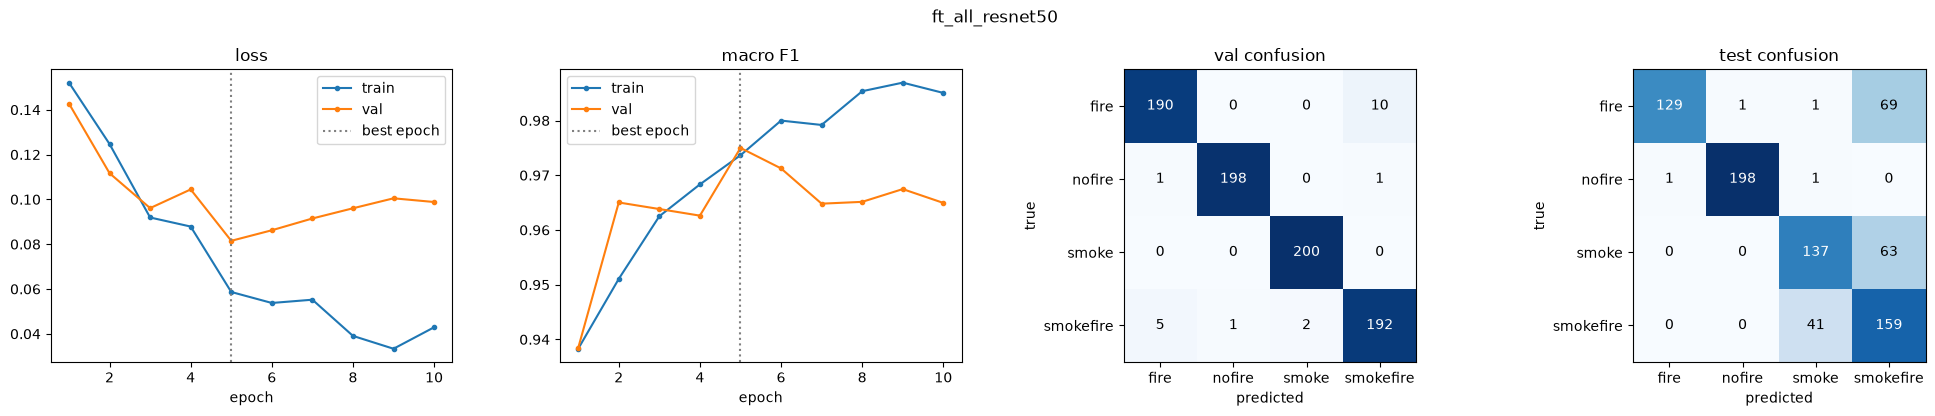

,task,run,trainable_params,total_params,best_epoch,epochs_run,train_minutes,val_acc,val_f1,test_acc,test_f1,test_f1_fire,test_f1_nofire,test_f1_smoke,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire,test_fire_or_smokefire_as_nofire
0,4 fine-tune: stage 1 (frozen),ft_stage1_xception,525572,21387052,6,10,3.2,0.88750,0.888385,0.71375,0.719545,0.698718,0.945813,0.669975,0.563674,61,82,9
1,4 fine-tune: stage 2 top,ft_top_xception,7301236,21387052,19,20,8.5,0.93750,0.937482,0.75875,0.765965,0.771084,0.977444,0.698980,0.616352,52,68,3
2,4 fine-tune: stage 2 all,ft_all_xception,21277996,21387052,19,20,15.5,0.96875,0.968836,0.77625,0.782808,0.762195,0.992443,0.715084,0.661509,28,74,0
3,4 fine-tune: stage 1 (frozen),ft_stage1_resnet50,525572,24113284,8,10,3.7,0.94625,0.945970,0.78000,0.785891,0.796407,0.975369,0.731959,0.639831,45,64,7
4,4 fine-tune: stage 2 top,ft_top_resnet50,15479044,24113284,7,12,5.5,0.97000,0.970043,0.77500,0.781243,0.792793,0.990000,0.681948,0.660232,29,66,2
5,4 fine-tune: stage 2 all,ft_all_resnet50,24007044,24113284,5,10,7.1,0.97500,0.974989,0.77875,0.785752,0.781818,0.992481,0.721053,0.647658,41,69,1


In [3]:
rows = []
for name in experiment.BACKBONES:
    keras.backend.clear_session()
    keras.utils.set_random_seed(config.RANDOM_SEED)
    model, base = build_motif(name)

    run = f"ft_stage1_{name}"
    print(f"=== {run}: {experiment.count_params(model)[1]:,} trainable parameters")
    experiment.compile_model(model, keras.optimizers.Adam(1e-3))
    fit_info = experiment.fit(model, run, datasets, epochs=10, monitor="val_f1")
    rows.append(experiment.evaluate(model, run, "4 fine-tune: stage 1 (frozen)", frames, datasets, fit_info,
                                    {**STAGE1, "backbone": name}))
    stage1_weights = config.MODELS_DIR / f"{run}.weights.h5"

    for scope in ["top", "all"]:
        model.load_weights(stage1_weights)
        experiment.unfreeze(base, name, scope)
        run = f"ft_{scope}_{name}"
        print(f"=== {run}: {experiment.count_params(model)[1]:,} trainable parameters")
        experiment.compile_model(model, keras.optimizers.Adam(1e-5))
        fit_info = experiment.fit(model, run, datasets, epochs=20, monitor="val_f1", early_stopping=5)
        rows.append(experiment.evaluate(model, run, f"4 fine-tune: stage 2 {scope}", frames, datasets,
                                        fit_info, {**STAGE2, "backbone": name, "unfrozen": scope}))
pd.DataFrame(rows)

## All runs so far

In [4]:
board = pd.read_csv(config.RESULTS_DIR / "leaderboard.csv")
board[["task", "run", "trainable_params", "best_epoch", "val_acc", "val_f1", "test_acc", "test_f1",
       "test_f1_smokefire", "test_smokefire_as_smoke", "test_fire_as_smokefire"]].round(4)

,task,run,trainable_params,best_epoch,val_acc,val_f1,test_acc,test_f1,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire
0,1 basic NN,basic_nn,3147012,28,0.6863,0.6792,0.6050,0.6088,0.4637,107,50
1,2 custom CNN,custom_cnn,2738340,46,0.9563,0.9564,0.7625,0.7648,0.6845,19,72
2,3 frozen backbone,frozen_xception,1052164,15,0.8988,0.8990,0.7388,0.7462,0.6071,48,72
3,3 frozen backbone,frozen_resnet50,1052164,11,0.9463,0.9463,0.7775,0.7840,0.6473,44,68
4,4 fine-tune: stage 1 (frozen),ft_stage1_xception,525572,6,0.8875,0.8884,0.7137,0.7195,0.5637,61,82
5,4 fine-tune: stage 2 top,ft_top_xception,7301236,19,0.9375,0.9375,0.7588,0.7660,0.6164,52,68
6,4 fine-tune: stage 2 all,ft_all_xception,21277996,19,0.9688,0.9688,0.7762,0.7828,0.6615,28,74
7,4 fine-tune: stage 1 (frozen),ft_stage1_resnet50,525572,8,0.9463,0.9460,0.7800,0.7859,0.6398,45,64
8,4 fine-tune: stage 2 top,ft_top_resnet50,15479044,7,0.9700,0.9700,0.7750,0.7812,0.6602,29,66
9,4 fine-tune: stage 2 all,ft_all_resnet50,24007044,5,0.9750,0.9750,0.7788,0.7858,0.6477,41,69
